# Task 1: Review Relevance Filtering (NLI-style relevance model)

Review adalah **premise**, konteks game adalah **hypothesis**, model melihat keduanya.
Output per review: `relevant` / `not_relevant` dan skor dalam rentang [0, 1].

| Section | BEAM element | Module |
|---|---|---|
| 1 Load reviews | Data: *Steam Reviews Dataset (raw)* | `src.phase1.data.load_reviews` |
| 2 Quality rules | Semantic Model: *Review Quality Rules*, Engineering: *Define Quality / Spam Heuristic Rules* (Developer) | `src.phase1.data.quality_filter` |
| 3 Quality filtering | Inference: *Quality Filtering* -> Data: *Content-bearing Reviews* | `src.phase1.data.quality_filter` |
| 4 Game context | Data: *Steam Games Dataset*, Transformation: *Join by app_id* -> *Review-Game Pairs* | `src.phase1.data.build_context`, `src.phase1.data.steam_api` |
| 5 Sample + split | Data (cap per game, split by app_id) | `src.phase1.data.sample_reviews`, `src.phase1.data.split` |
| 6 Pairs | Engineering: *Negative Sampling & Labeling* -> Data: *Labeled Pairs* | `src.phase1.data.make_pairs` |
| 7 Annotation | Actor: *Annotator* (gold test set) | `src.phase1.data.export_annotation`, `src.phase1.data.import_annotation` |
| 8 Models | Training: *Train Relevance Classifier* -> Statistical Model: *NLI / Relevance Model* | `src.phase1.models.*` |
| 9 Inference | Inference: *Relevance Filtering* -> `data/output/relevant_reviews.parquet` for Tasks 2 and 3 | `src.phase1.inference.score_reviews` |

## 0. Setup

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import torch

from src.phase1.utils.io import load_config, stage_path, write_parquet, read_parquet, run_dir, resolve
from src.phase1.utils.seed import set_seed

CONFIG = os.environ.get("TASK1_CONFIG", "configs/phase1.yaml")
RUN_ZERO_SHOT = True   # bart-large-mnli, ~1.6 GB download on first use
RUN_ABLATIONS = False   # hard_ratio 0.0 vs 0.5, with vs without quality filter

cfg = load_config(CONFIG)
set_seed(cfg["seed"])
pl.Config.set_fmt_str_lengths(90);
pl.Config.set_tbl_rows(50)

print("config:", CONFIG, "| limit:", cfg["limit"], "| seed:", cfg["seed"], "| label scheme:", cfg["pairs"]["label_scheme"])
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

config: configs/phase1.yaml | limit: None | seed: 42 | label scheme: binary
torch 2.14.1+cu126 | CUDA available: True | NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Load reviews (BEAM: Data, *Steam Reviews Dataset (raw)*)
Hanya membaca kolom yang dibutuhkan secara lazy dengan polars, membersihkan teks, dan memberi tiap review `review_id` yang stabil.
Jika `limit` diatur di `configs/phase1.yaml`, game dipertahankan utuh (seeded) sehingga run kecil tetap berisi game yang lengkap.

In [2]:
from src.phase1.data.build_context import inspect_sources
inspect_sources(cfg)   # verify file names, headers and list-column formats before trusting the parsers

[nikdavis steam.csv] columns: ['appid', 'name', 'release_date', 'english', 'developer', 'publisher', 'platforms', 'required_age', 'categories', 'genres', 'steamspy_tags', 'achievements', 'positive_ratings', 'negative_ratings', 'average_playtime', 'median_playtime', 'owners', 'price']
   genres: ['Action', 'Action', 'Action']
   categories: ['Multi-player;Online Multi-Player;Local Multi-Player;Valve Anti-Cheat enabled', 'Multi-player;Online Multi-Player;Local Multi-Player;Valve Anti-Cheat enabled', 'Multi-player;Valve Anti-Cheat enabled']
[nikdavis steam_description_data.csv] columns: ['steam_appid', 'detailed_description', 'about_the_game', 'short_description']
[artermiloff] columns: ['appid', 'name', 'release_date', 'required_age', 'price', 'dlc_count', 'detailed_description', 'about_the_game', 'short_description', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'achievements', 'recommendations', 'n

In [3]:
from src.phase1.data.load_reviews import load_reviews
reviews = load_reviews(cfg)
write_parquet(reviews, stage_path(cfg, "interim", "reviews.parquet"))
print(reviews.height, "reviews,", reviews["app_id"].n_unique(), "games")
reviews.head(5)

23:45:44 INFO load_reviews: load_reviews: 6417106 rows in, 6417106 rows out (0 dropped)


6417106 reviews, 9972 games


review_id,app_id,app_name,review_text,review_score,review_votes
u32,i64,str,str,i8,i8
0,10,"""Counter-Strike""","""Ruined my life.""",1,0
1,10,"""Counter-Strike""","""This will be more of a ''my experience with this game'' type of review, because saying thi…",1,1
2,10,"""Counter-Strike""","""This game saved my virginity.""",1,0
3,10,"""Counter-Strike""","""• Do you like original games? • Do you like games that don't lag? • Do you like games you …",1,0
4,10,"""Counter-Strike""","""Easy to learn, hard to master.""",1,1


## 2. Quality rules (BEAM: Engineering *Define Quality / Spam Heuristic Rules* -> Semantic Model *Review Quality Rules*)
Rule sederhana dan mudah dijelaskan (tanpa LLM): empty/placeholder, ASCII art, repeated characters, repeated words, too short,
duplicate dalam satu game, non-English. Tiap rule adalah fungsi tersendiri di `src/phase1/data/quality_filter.py`, dan setiap baris yang ditolak
mencatat rule pertama yang terpicu. Threshold ada di `configs/phase1.yaml`; lihat distribusinya di bawah sebelum mengunci nilainya.

In [4]:
from src.phase1.data.quality_filter import review_stats

stats = review_stats(reviews.sample(n=min(50_000, reviews.height), seed=cfg["seed"]))
q = [0.01, 0.05, 0.5, 0.95, 0.99]
pct = pl.DataFrame({"percentile": q}).with_columns(
    *[pl.Series(c, [stats[c].quantile(p) for p in q]) for c in ["n_words", "nonalnum_ratio", "max_char_run", "unique_word_ratio"]])
print("current thresholds:", {k: cfg["quality"][k] for k in ["min_tokens", "max_nonalnum_ratio", "max_char_run", "min_unique_word_ratio"]})
pct

current thresholds: {'min_tokens': 3, 'max_nonalnum_ratio': 0.5, 'max_char_run': 8, 'min_unique_word_ratio': 0.3}


percentile,n_words,nonalnum_ratio,max_char_run,unique_word_ratio
f64,f64,f64,f64,f64
0.01,2.0,0.0,1.0,0.523077
0.05,3.0,0.0,1.0,0.628205
0.5,20.0,0.033932,2.0,0.928571
0.95,230.0,0.095238,2.0,1.0
0.99,543.0,0.2,4.0,1.0


## 3. Quality filtering (BEAM: Inference *Quality Filtering* -> Data *Content-bearing Reviews*)

In [5]:
from src.phase1.data.quality_filter import apply_rules, rule_summary

kept, rejected = apply_rules(reviews, cfg["quality"])
write_parquet(kept, stage_path(cfg, "interim", "reviews_filtered.parquet"))
write_parquet(rejected, stage_path(cfg, "interim", "reviews_rejected.parquet"))
print(f"{reviews.height} in -> {kept.height} kept, {rejected.height} rejected")
rule_summary(rejected, reviews.height)

23:45:59 INFO quality_filter: rule empty_or_placeholder   fired on 1037222 of 6417106
23:48:00 INFO quality_filter: rule ascii_art              fired on 6446 of 5379884
23:50:19 INFO quality_filter: rule repeated_chars         fired on 4953 of 5373438
23:50:58 INFO quality_filter: rule repeated_words         fired on 2455 of 5368485
23:51:45 INFO quality_filter: rule too_short              fired on 136261 of 5366030
23:52:06 INFO quality_filter: rule duplicate_in_game      fired on 734439 of 5229769
23:53:55 INFO quality_filter: rule non_english            fired on 2057 of 4495330


6417106 in -> 4493273 kept, 1923833 rejected


rule_name,n_rejected,share_of_input
str,u32,f64
"""empty_or_placeholder""",1037222,0.161634
"""duplicate_in_game""",734439,0.11445
"""too_short""",136261,0.021234
"""ascii_art""",6446,0.001005
"""repeated_chars""",4953,0.000772
"""repeated_words""",2455,0.000383
"""non_english""",2057,0.000321


In [6]:
# inspect what each rule rejects before trusting its threshold (tune in the config, rerun sections 2-3)
for rule in rejected["rule_name"].unique().sort().to_list():
    sub = rejected.filter(pl.col("rule_name") == rule)
    print(f"--- {rule} ({sub.height})")
    for t in sub.sample(n=min(4, sub.height), seed=cfg["seed"])["review_text"].to_list():
        print("   ", t[:140].replace("\n", " "))

--- ascii_art (6446)
    ……(\_/) ……( ‘_’) …./”'”'”'”'”'”'\======░ /”'”'”'”'”'”'”'”'”'”\ \_@_@_@_@_@_/
    ....................../´¯/) ....................,/¯../ .................../..../ ............./´¯/'...'/´¯¯`·¸ ........../'/.../..../.......
    ( ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°) ͡° ͜ʖ ͡°
    ( ͡° ͜ʖ ͡°)
--- duplicate_in_game (734439)
    Disgaea is one of my favorite games, and it's held up rather well to the test of time. Having it on the PC is amazing, and Disgaea 2 is comi
    this is the most horrendous, yet hilarious surgery game i've ever seen. good luck holding the tools lol. For half off, definitely worth the 
    Best Game of 2013
    Amazing! I want more.
--- empty_or_placeholder (1037222)
    Early Access Review
    Early Access Review
    Early Access Review
    Early Access Review
--- non_english (2057)
    When you have a hard day this cools you off ／ﾌﾌ ム｀ヽ / ノ) ） ヽ / ｜ 

## 4. Game context (BEAM: Transformation *Join by app_id*)
Genre dan deskripsi **tidak ada** di dataset review, jadi digabungkan manual lewat `app_id`:
genres/categories: nikdavis -> artermiloff -> Steam API; description: artermiloff -> nikdavis -> Steam API.
Game yang masih kekurangan genre atau deskripsi dibuang dan dihitung. Respons API di-cache di
`data/raw/steam_api/cache.jsonl` (termasuk `success: false`), sehingga rerun tidak pernah meminta `app_id` yang sama dua kali.

In [7]:
from src.phase1.data.build_context import build_game_context

names = dict(kept.group_by("app_id").agg(pl.col("app_name").first()).iter_rows())
context, coverage = build_game_context(sorted(names), names, cfg)
write_parquet(context, stage_path(cfg, "interim", "game_context.parquet"))
print("coverage report (share of review app_ids):")
display(coverage)
print(context["context_text"][0])
context.head(5)

23:54:01 INFO steam_api: steam api: 532 requested, 532 cached, 0 to fetch
23:54:01 INFO build_context: build_context (app_ids): 9090 rows in, 8747 rows out (343 dropped)


coverage report (share of review app_ids):


field,source,n_app_ids,share
str,str,i64,f64
"""src_genres""","""api""",192,0.021122
"""src_genres""","""artermiloff""",357,0.039274
"""src_genres""","""missing""",338,0.037184
"""src_genres""","""nikdavis""",8203,0.90242
"""src_description""","""api""",194,0.021342
"""src_description""","""artermiloff""",7448,0.819362
"""src_description""","""missing""",325,0.035754
"""src_description""","""nikdavis""",1123,0.123542
"""overall""","""dropped (missing genres or description)""",343,0.037734


Genres: Action. Categories: Multi-player, Online Multi-Player, Local Multi-Player. Description: Play the world's number 1 online action game. Engage in an incredibly realistic brand of terrorist warfare in this wildly popular team-based game. Ally with teammates to complete strategic missions. Take out enemy sites. Rescue hostages. Your role affects your team's success. Your team's success affects your role.


app_id,name,genres,categories,description,context_text,src_genres,src_description
i64,str,list[str],list[str],str,str,str,str
10,"""Counter-Strike""","[""Action""]","[""Multi-player"", ""Online Multi-Player"", ""Local Multi-Player""]","""Play the world's number 1 online action game. Engage in an incredibly realistic brand of t…","""Genres: Action. Categories: Multi-player, Online Multi-Player, Local Multi-Player. Descrip…","""nikdavis""","""nikdavis"""
20,"""Team Fortress Classic""","[""Action""]","[""Multi-player"", ""Online Multi-Player"", ""Local Multi-Player""]","""One of the most popular online action games of all time, Team Fortress Classic features ov…","""Genres: Action. Categories: Multi-player, Online Multi-Player, Local Multi-Player. Descrip…","""nikdavis""","""artermiloff"""
30,"""Day of Defeat""","[""Action""]","[""Multi-player""]","""Enlist in an intense brand of Axis vs. Allied teamplay set in the WWII European Theatre of…","""Genres: Action. Categories: Multi-player. Description: Enlist in an intense brand of Axis …","""nikdavis""","""nikdavis"""
40,"""Deathmatch Classic""","[""Action""]","[""Multi-player"", ""Online Multi-Player"", ""Local Multi-Player""]","""Enjoy fast-paced multiplayer gaming with Deathmatch Classic (a.k.a. DMC). Valve's tribute …","""Genres: Action. Categories: Multi-player, Online Multi-Player, Local Multi-Player. Descrip…","""nikdavis""","""nikdavis"""
50,"""Half-Life: Opposing Force""","[""Action""]","[""Single-player"", ""Multi-player""]","""Return to the Black Mesa Research Facility as one of the military specialists assigned to …","""Genres: Action. Categories: Single-player, Multi-player. Description: Return to the Black …","""nikdavis""","""nikdavis"""


## 5. Sample per game and split by game (BEAM: Data)
Maksimal `max_reviews_per_game` review per game (stratified berdasarkan `review_score`), hanya game dengan minimal `min_reviews_per_game` review.
Split berdasarkan `app_id` (80/10/10): satu game hanya muncul di satu split, dan negative hanya diambil dari dalam split yang sama.

In [8]:
from src.phase1.data.sample_reviews import sample_reviews
from src.phase1.data.split import split_reviews, SPLITS

sampled = sample_reviews(kept, context["app_id"].to_list(), cfg["sampling"], cfg["seed"])
write_parquet(sampled, stage_path(cfg, "interim", "reviews_sampled.parquet"))
parts = split_reviews(sampled, context, cfg["split"], cfg["seed"])
for name, df in parts.items():
    write_parquet(df, stage_path(cfg, "processed", f"split_{name}.parquet"))

# leakage guarantee: no app_id in more than one split
owner = {}
for name, df in parts.items():
    for a in df["app_id"].unique().to_list():
        assert a not in owner, f"app_id {a} in both {owner[a]} and {name}"
        owner[a] = name
pl.DataFrame({"split": list(parts), "reviews": [d.height for d in parts.values()],
              "games": [d["app_id"].n_unique() for d in parts.values()]})

split,reviews,games
str,i64,i64
"""train""",238718,5989
"""val""",29727,749
"""test""",29863,749


## 6. Negative sampling and labeling (BEAM: Engineering -> Data *Labeled Pairs*)
Untuk setiap review: game miliknya sendiri adalah `positive`; game lain dengan genre yang sama adalah `hard_negative`; game tanpa genre yang sama
adalah `random_negative`. `neg_per_pos` dan `hard_ratio` berasal dari config (ablation: 0.0 vs 0.5).

In [9]:
from src.phase1.data.make_pairs import build_pairs

rejected_df = read_parquet(stage_path(cfg, "interim", "reviews_rejected.parquet"))
pairs = {}
for name in SPLITS:
    pairs[name] = build_pairs(parts[name], context, cfg["pairs"], name, cfg["seed"], rejected_df)
    write_parquet(pairs[name], stage_path(cfg, "processed", f"pairs_{name}.parquet"))

# leakage guarantee: no pair crosses a split
for name, df in pairs.items():
    assert all(owner[a] == name for a in df["app_id"].unique().to_list() + df["paired_app_id"].unique().to_list())
display(pl.concat(pairs.values()).group_by("split", "pair_type").len().sort("split", "pair_type"))
ex = pairs["train"].filter(pl.col("pair_type") == "hard_negative").head(1)
print("review :", ex["review_text"][0][:200]); print("context:", ex["context_text"][0][:250]); print("label  :", ex["label"][0])

23:54:17 WARNING make_pairs: test: 36 negatives drawn from the other pool (no candidates of the requested kind)


split,pair_type,len
str,str,u32
"""test""","""hard_negative""",29818
"""test""","""positive""",29863
"""test""","""random_negative""",29908
"""train""","""hard_negative""",239090
"""train""","""positive""",238718
"""train""","""quality_reject""",11022
"""train""","""random_negative""",238346
"""val""","""hard_negative""",29661
"""val""","""positive""",29727


review : Great for older Counter Strike players and newer ones to experience what older players had with this game :)
context: Genres: Action; Indie; RPG. Categories: Single-player. Description: Faron's Fate is an action- roguelike about a lone adventurer venturing into a dungeon full of dangerous monsters and rare artifacts. Enter a procedurally generated dungeon, fight for
label  : 0


## 7. Annotation (BEAM: Actor *Annotator*)
Export sampel stratified dari **test split saja**. Annotator mengisi `gold_label` di `annotation/labeled.txt` (salinan `to_label.txt`, dipisah `|`; CSV yang disimpan ulang dari Excel sebagai `labeled.csv` juga bisa):
(1) review game sendiri yang sebenarnya off-topic -> 0, (2) hard negative yang sebenarnya relevan -> 1 (graded scheme).
Selama `labeled.txt` / `labeled.csv` belum ada, notebook memakai auto label dan menandainya `label_source = auto`; **metrik baru benar-benar gold setelah dilabeli manusia**.

In [10]:
from src.phase1.data.export_annotation import export_annotation
from src.phase1.data.import_annotation import import_annotation
from src.phase1.utils.io import read_annotation_file, write_annotation_file

to_label = export_annotation(pairs["test"], context, cfg["annotation"], cfg["seed"])
write_annotation_file(to_label, stage_path(cfg, "annotation", "to_label.txt"))  # '|'-separated
labeled_path = next((p for n in ("labeled.txt", "labeled.csv")
                     if (p := stage_path(cfg, "annotation", n)).exists()), None)
labeled = read_annotation_file(labeled_path) if labeled_path else None
gold = import_annotation(pairs["test"], labeled, cfg["pairs"]["label_scheme"], cfg["annotation"]["allow_auto_labels"], to_label)
write_parquet(gold, stage_path(cfg, "processed", "gold_test.parquet"))
print("gold rows:", gold.height, "| label source:", gold["label_source"].unique().to_list())
gold.group_by("pair_type").len()

23:54:17 WARNING import_annotation: no labeled.txt/.csv: using AUTO labels as gold_label (label_source=auto). Metrics are NOT gold.


gold rows: 600 | label source: ['auto']


pair_type,len
str,u32
"""positive""",300
"""hard_negative""",210
"""random_negative""",90


## 8. Models (BEAM: Training *Train Relevance Classifier* -> Statistical Model *NLI / Relevance Model*)
Threshold dipilih di val dan dilaporkan pada gold test set. Hasil run ditulis ke `models/phase1/<run_name>/`
(`metrics.json`, `errors.csv`, `model_info.json`, config + git hash + seed).

### 8a. `lexical_baseline`: is word overlap enough?

In [11]:
from src.phase1.models import lexical_baseline
m_lex = lexical_baseline.run(cfg, pairs["train"], pairs["val"], gold)
m_lex

23:54:51 INFO evaluate: lexical_baseline: P=0.813 R=0.450 F1=0.579 Acc=0.673 @thr=0.01 (['auto'] labels)


{'n': 600,
 'threshold': 0.01,
 'precision': 0.8132530120481928,
 'recall': 0.45,
 'f1': 0.5793991416309013,
 'accuracy': 0.6733333333333333,
 'by_pair_type': {'random_negative': {'n': 90,
   'accuracy': 0.9111111111111111,
   'share_predicted_relevant': 0.08888888888888889},
  'positive': {'n': 300, 'accuracy': 0.45, 'share_predicted_relevant': 0.45},
  'hard_negative': {'n': 210,
   'accuracy': 0.8904761904761904,
   'share_predicted_relevant': 0.10952380952380952}},
 'run_name': 'lexical_baseline',
 'label_source': ['auto'],
 'val_f1_at_threshold': 0.5303341269189722}

### 8b. `zero_shot_nli`: bart-large-mnli, no fine-tuning

In [12]:
if RUN_ZERO_SHOT:
    from src.phase1.models import zero_shot_nli
    m_zs = zero_shot_nli.run(cfg, pairs["val"], gold)
    torch.cuda.empty_cache()
    display(m_zs)
else:
    print("skipped (RUN_ZERO_SHOT is off)")

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

zero-shot: 100%|██████████| 38/38 [00:05<00:00,  7.38it/s]
23:55:23 INFO evaluate: zero_shot_nli: P=0.500 R=1.000 F1=0.667 Acc=0.500 @thr=0.00 (['auto'] labels)


{'n': 600,
 'threshold': 0.0,
 'precision': 0.5,
 'recall': 1.0,
 'f1': 0.6666666666666666,
 'accuracy': 0.5,
 'by_pair_type': {'hard_negative': {'n': 210,
   'accuracy': 0.0,
   'share_predicted_relevant': 1.0},
  'random_negative': {'n': 90,
   'accuracy': 0.0,
   'share_predicted_relevant': 1.0},
  'positive': {'n': 300, 'accuracy': 1.0, 'share_predicted_relevant': 1.0}},
 'run_name': 'zero_shot_nli',
 'label_source': ['auto'],
 'val_f1_at_threshold': 0.5057900635039223}

### 8c. `task_adapted`: cross-encoder fine-tuned on our pairs (main model)
`roberta-base` pada pasangan `(review, context)`, fp16 di GPU. Binary scheme: score = P(relevant); graded scheme: regression, score = prediction / 2.

In [13]:
from src.phase1.models import train_cross_encoder
m_ta = train_cross_encoder.run(cfg, pairs["train"], pairs["val"], gold)
m_ta

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
val: 100%|██████████| 157/157 [00:29<00:00,  5.28it/s]
00:44:10 INFO train_cross_encoder: epoch 1: train_loss=0.4294 val_f1=0.7389 thr=0.36


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

val: 100%|██████████| 157/157 [00:29<00:00,  5.35it/s]
01:33:33 INFO train_cross_encoder: epoch 2: train_loss=0.3178 val_f1=0.7573 thr=0.40


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

val: 100%|██████████| 157/157 [00:29<00:00,  5.31it/s]
02:22:38 INFO train_cross_encoder: epoch 3: train_loss=0.2614 val_f1=0.7632 thr=0.41


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

cross-encoder: 100%|██████████| 10/10 [00:01<00:00,  6.16it/s]
02:23:13 INFO evaluate: task_adapted: P=0.873 R=0.730 F1=0.795 Acc=0.812 @thr=0.41 (['auto'] labels)


{'n': 600,
 'threshold': 0.41000000000000003,
 'precision': 0.8725099601593626,
 'recall': 0.73,
 'f1': 0.79491833030853,
 'accuracy': 0.8116666666666666,
 'by_pair_type': {'positive': {'n': 300,
   'accuracy': 0.73,
   'share_predicted_relevant': 0.73},
  'hard_negative': {'n': 210,
   'accuracy': 0.861904761904762,
   'share_predicted_relevant': 0.1380952380952381},
  'random_negative': {'n': 90,
   'accuracy': 0.9666666666666667,
   'share_predicted_relevant': 0.03333333333333333}},
 'run_name': 'task_adapted',
 'label_source': ['auto'],
 'val_f1_at_threshold': 0.7632277196815983}

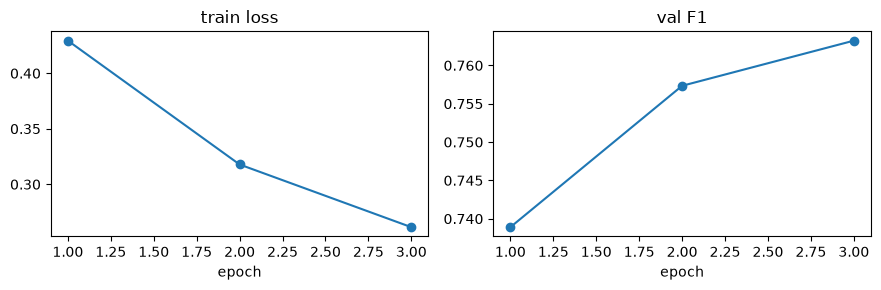

In [14]:
log = json.loads((run_dir(cfg, cfg["run_name"]) / "train_log.json").read_text())
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot([r["epoch"] for r in log], [r["train_loss"] for r in log], marker="o"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot([r["epoch"] for r in log], [r["val_f1"] for r in log], marker="o"); ax[1].set_title("val F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

### 8d. `cross_genre`: domain-mismatch test
Membutuhkan `configs/phase1_genre_holdout.yaml` dengan `split.holdout_genres` yang diisi (keputusan tim yang masih terbuka). Ini menjalankan ulang section 5-7 dengan
genre-holdout split dan melatih cross-encoder yang sama, sehingga game test berasal dari genre yang tidak pernah dilihat saat training.

In [15]:
hold_cfg = load_config("configs/phase1_genre_holdout.yaml")
if not hold_cfg["split"]["holdout_genres"]:
    print("skipped: set split.holdout_genres in configs/phase1_genre_holdout.yaml first (which genres to hold out is an open decision)")
else:
    hold_cfg.update(limit=cfg["limit"]); hold_cfg["paths"]["interim_dir"] = cfg["paths"]["interim_dir"]
    hold_cfg["paths"]["outputs_dir"] = cfg["paths"]["outputs_dir"]
    hparts = split_reviews(sampled, context, hold_cfg["split"], hold_cfg["seed"])
    hpairs = {n: build_pairs(hparts[n], context, hold_cfg["pairs"], n, hold_cfg["seed"], rejected_df) for n in SPLITS}
    hgold = import_annotation(hpairs["test"], None, hold_cfg["pairs"]["label_scheme"], True,
                              export_annotation(hpairs["test"], context, hold_cfg["annotation"], hold_cfg["seed"]))
    m_cg = train_cross_encoder.run(hold_cfg, hpairs["train"], hpairs["val"], hgold, run_name="cross_genre")
    display(m_cg)

skipped: set split.holdout_genres in configs/phase1_genre_holdout.yaml first (which genres to hold out is an open decision)


### 8e. Ablations (optional, `RUN_ABLATIONS = True`)
Model yang sama, masing-masing satu perubahan: `hard_ratio` 0.0 vs 0.5; dengan vs tanpa quality filter.

In [16]:
import copy
if RUN_ABLATIONS:
    # hard_ratio = 0.0 (the default run above uses 0.5)
    c0 = copy.deepcopy(cfg); c0["pairs"]["hard_ratio"] = 0.0
    p0 = {n: build_pairs(parts[n], context, c0["pairs"], n, c0["seed"]) for n in SPLITS}
    train_cross_encoder.run(c0, p0["train"], p0["val"], gold, run_name="ablation_hard_ratio_0")

    # without the quality filter: sample from the unfiltered reviews
    raw_sampled = sample_reviews(reviews, context["app_id"].to_list(), cfg["sampling"], cfg["seed"])
    rparts = split_reviews(raw_sampled, context, cfg["split"], cfg["seed"])
    rp = {n: build_pairs(rparts[n], context, cfg["pairs"], n, cfg["seed"]) for n in SPLITS}
    train_cross_encoder.run(cfg, rp["train"], rp["val"], gold, run_name="ablation_no_quality_filter")
else:
    print("skipped (set RUN_ABLATIONS = True to run)")

skipped (set RUN_ABLATIONS = True to run)


## 9. Results on the gold test set

In [17]:
rows = []
for d in sorted(resolve(cfg["paths"]["outputs_dir"]).iterdir()):
    f = d / "metrics.json"
    if f.exists():
        m = json.loads(f.read_text())
        rows.append({"run": d.name, "precision": m["precision"], "recall": m["recall"], "f1": m["f1"], "accuracy": m["accuracy"],
                     "threshold": m["threshold"], "n": m["n"], "labels": ",".join(m["label_source"]),
                     **{f"acc_{k}": v["accuracy"] for k, v in m["by_pair_type"].items()}})
results = pl.DataFrame(rows)
if results.height and results["labels"].str.contains("auto").any():
    print("WARNING: some runs use auto labels, not human gold labels")
results

run,precision,recall,f1,accuracy,threshold,n,labels,acc_random_negative,acc_positive,acc_hard_negative
str,f64,f64,f64,f64,f64,i64,str,f64,f64,f64
"""lexical_baseline""",0.813253,0.45,0.579399,0.673333,0.01,600,"""auto""",0.911111,0.45,0.890476
"""task_adapted""",0.87251,0.73,0.794918,0.811667,0.41,600,"""auto""",0.966667,0.73,0.861905
"""zero_shot_nli""",0.5,1.0,0.666667,0.5,0.0,600,"""auto""",0.0,1.0,0.0


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

cross-encoder: 100%|██████████| 10/10 [00:01<00:00,  5.45it/s]


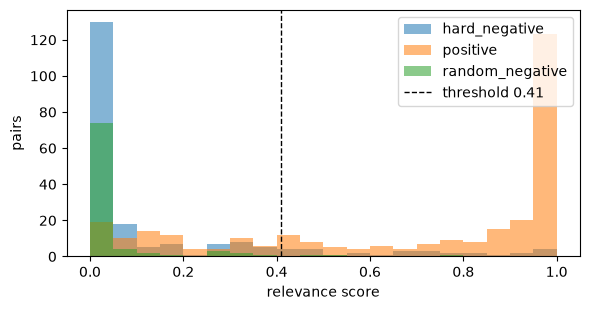

In [18]:
# score distribution per pair type for the main model (does it separate positives from negatives?)
test_scored = train_cross_encoder.CrossEncoderScorer(run_dir(cfg, cfg["run_name"]) / "model", cfg["models"]["cross_encoder"],
                                                     cfg["pairs"]["label_scheme"])
g = gold.with_columns(pl.Series("score", test_scored.score(gold["review_text"].to_list(), gold["context_text"].to_list())))
thr = json.loads((run_dir(cfg, cfg["run_name"]) / "model_info.json").read_text())["threshold"]
fig, ax = plt.subplots(figsize=(6, 3.2))
for ptype in g["pair_type"].unique().sort().to_list():
    ax.hist(g.filter(pl.col("pair_type") == ptype)["score"].to_numpy(), bins=20, range=(0, 1), alpha=0.55, label=ptype)
ax.axvline(thr, color="k", ls="--", lw=1, label=f"threshold {thr:.2f}")
ax.set_xlabel("relevance score"); ax.set_ylabel("pairs"); ax.legend(); plt.tight_layout(); plt.show()

In [19]:
# error analysis: misclassified gold pairs (tag sarcasm / hyperbole cases in errors.csv's error_tag column)
errors = pl.read_csv(run_dir(cfg, cfg["run_name"]) / "errors.csv")
print(errors.height, "errors")
errors.select("pair_type", "label", "score", "review_text").head(8)

113 errors


pair_type,label,score,review_text
str,i64,f64,str
"""random_negative""",0,0.481743,"""THIS GAME IS A 2008 PEICE OF ♥♥♥♥!!"""
"""hard_negative""",0,0.9470392,"""no one shoots my buddies but me"""
"""positive""",1,0.008985,"""Really really fun game to play drunk with friends."""
"""positive""",1,0.3719347,"""Game would be great if you could use wide screen resolution..."""
"""hard_negative""",0,0.423652,"""Cannot recommend. After awhile my saved games were unable to open and had to start a new g…"
"""positive""",1,0.14682,"""I bought Krater a while ago. this game was originally sold on the idea that you'd have a p…"
"""hard_negative""",0,0.5788202,"""Funny Sequel to funny RPG, this was as funny as the first part. Great!"""
"""positive""",1,0.001617,"""I almost quit this game after 5 minutes. Another TD game was frustrating me, this one seem…"


## 10. Relevance filtering (BEAM: Inference *Relevance Filtering*)
Beri skor setiap review terhadap **game miliknya sendiri** dengan model utama, lalu tulis output contract untuk Task 2 dan 3:
`data/output/relevant_reviews.parquet` dengan `review_id, app_id, app_name, review_text, relevance_score, is_relevant, score_band, rejected_by, model_run`.
Reject dari quality rule disertakan dengan skor 0.0. Setelah itu `python -m src.phase1.inference.export_outputs` menulis file CSV / JSON untuk Phase 2 dan annotator.

In [20]:
from src.phase1.inference.bands import margin_from
from src.phase1.inference.score_reviews import load_scorer, score_reviews, select_input, select_rejected, OUTPUT_COLUMNS

scorer, threshold = load_scorer(cfg, cfg["run_name"])
to_score = select_input(cfg)
relevant = score_reviews(to_score, context, scorer, threshold, cfg["run_name"],
                         rejected=select_rejected(cfg, to_score["app_id"].unique()), margin=margin_from(cfg))
assert relevant.columns == OUTPUT_COLUMNS
write_parquet(relevant, stage_path(cfg, "export", "relevant_reviews.parquet"))
print(f"{relevant.height} reviews scored, {relevant['is_relevant'].mean():.1%} relevant at threshold {threshold:.2f}")
display(relevant["score_band"].value_counts())
relevant.sort("relevance_score").head(5)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

cross-encoder: 100%|██████████| 301/301 [00:53<00:00,  5.65it/s]


1333309 reviews scored, 71.6% relevant at threshold 0.41


score_band,count
str,u32
"""borderline""",209950
"""off_topic""",270459
"""relevant""",852900


review_id,app_id,app_name,review_text,relevance_score,is_relevant,score_band,rejected_by,model_run
u32,i64,str,str,f32,bool,str,str,str
3543934,287980,"""Mini Metro""","""Early Access Review""",0.0,false,"""off_topic""","""empty_or_placeholder""","""task_adapted"""
2431779,244210,"""Assetto Corsa""","""Early Access Review""",0.0,false,"""off_topic""","""empty_or_placeholder""","""task_adapted"""
3232743,270450,"""Robot Roller-Derby Disco Dodgeball""","""Early Access Review""",0.0,false,"""off_topic""","""empty_or_placeholder""","""task_adapted"""
1554649,22380,"""Fallout: New Vegas""","""great game""",0.0,false,"""off_topic""","""too_short""","""task_adapted"""
2753105,252490,"""Rust""","""Early Access Review""",0.0,false,"""off_topic""","""empty_or_placeholder""","""task_adapted"""


In [21]:
# the reviews the model drops: should look like off-topic text, not like game talk
relevant.filter(~pl.col("is_relevant")).sample(n=min(8, int((~relevant["is_relevant"]).sum())), seed=cfg["seed"]) \
        .select("relevance_score", "review_text")

relevance_score,review_text
f32,str
0.0,"""12/10 Wood Bad Rat agen . ………………_„-,-~''~''':::'':::':::::''::::''~ ………._,-'':::::::::::::…"
0.256785,"""This is the most shallow and boring rogue-like experience you could buy. Combat system is …"
0.0,"""Early Access Review"""
0.104249,"""Not as interesting as the concept sounds. Nice music though."""
0.353596,"""Great game just the same as 15 years ago.. :) Picked it up for 0.50€, totally worth. Still…"
0.387198,"""Is great :D"""
0.326271,"""Hey there Steam patron, allow me to give you a quick summary of MY experience of the game,…"
0.021636,"""its a rip off of star conflict and star conflict is a rip off of boundless"""


## Output
- Model + metrik: `models/phase1/<run_name>/` (`model/`, `metrics.json`, `errors.csv`, `model_info.json`, `run_meta.json`)
- Input Task 2 / Task 3: `data/output/relevant_reviews.parquet`